# SHADOW — Notebook 04: Baseline Model Training & Multimodal Evaluation

**Project:** SHADOW (Student-Built Multimodal Cybersecurity & Phishing Detection Platform)  
**Phase:** Phase 4 — Unified Baseline Classifier Training & Comprehensive Multimodal Benchmarking  
**Author:** Lead ML Research Assistant  
**Kernel:** Python (SHADOW Research)  

---

## 1. Research Objectives & Non-Negotiable Architecture Rules

In Notebooks 01 through 03, we audited 7 datasets, designed zero-leakage domain-grouped partitions, extracted 20 lexical URL features, 13 static HTML features, and 576-dimensional MobileNetV3 visual embeddings.

Now in **Notebook 04**, we train the **final phishing detection classifier** for Project SHADOW:

### Non-Negotiable Design Principles:
1. **EXACTLY ONE FINAL MODEL:** We train a **single unified LightGBM classifier** capable of accepting all available modalities (URL, HTML, Visual) simultaneously. We do **not** train isolated modality-specific silos.
2. **ZERO DOMAIN LEAKAGE:** The strict domain-aware partition assignments established in Notebook 02 are preserved. All novel domains from supplementary sets are partitioned deterministically to guarantee:
   $$\text{Domains}(\text{Train}) \cap \text{Domains}(\text{Val}) = \emptyset$$
   $$\text{Domains}(\text{Train}) \cap \text{Domains}(\text{Test}) = \emptyset$$
   $$\text{Domains}(\text{Val}) \cap \text{Domains}(\text{Test}) = \emptyset$$
3. **RIGOROUS DATA ALIGNMENT:** Synthetic behavioural telemetry is **strictly excluded** from supervised training because it lacks verified ground-truth URL pairing. URL, HTML, and visual modalities are aligned into a unified multi-table training matrix.
4. **EXPLICIT MISSING MODALITY HANDLING:** Real-world clients rarely observe all modalities simultaneously (e.g. an API check only sees the URL; a browser extension inspects HTML; a crawler captures screenshots). We employ LightGBM's native missing-value splitting paired with explicit binary indicators (`has_html_modality`, `has_visual_modality`).
5. **STRICT PREPROCESSING ISOLATION:** Any learned transformations are fit **strictly on training data**. Validation data is used solely for early stopping and probability threshold tuning; the test set remains untouched until final scientific reporting.


---
## 2. Environment Verification & ML Tooling Check

We verify our execution environment, GPU hardware, and machine learning dependencies (`scikit-learn`, `lightgbm`, `shap`, `torch`).


In [1]:
import os
import sys
import time
import math
import json
import shutil
import platform
import re
from pathlib import Path
from collections import Counter
from urllib.parse import urlparse, parse_qs

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import tldextract
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from sklearn.model_selection import GroupShuffleSplit
import lightgbm as lgb
import shap
import torch

# Dynamic Root Discovery
PROJECT_ROOT = Path(os.path.abspath("")).resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "ml-research" / "reports"
FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DOCS_RESEARCH = PROJECT_ROOT / "docs" / "research"

print(f"SHADOW Research Root: {PROJECT_ROOT}")
print(f"Python: {platform.python_version()} | Platform: {platform.platform()}")
print(f"LightGBM: {lgb.__version__} | Scikit-Learn: {sklearn.__version__} | SHAP: {shap.__version__}")
print(f"PyTorch CUDA: {torch.cuda.is_available()} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


SHADOW Research Root: C:\Dev\Hackathon\SHADOW
Python: 3.11.9 | Platform: Windows-10-10.0.26300-SP0
LightGBM: 4.7.0 | Scikit-Learn: 1.9.1 | SHAP: 0.51.0
PyTorch CUDA: True (NVIDIA GeForce RTX 4050 Laptop GPU)


---
## 3. Phase 1 — Data Validation, Alignment & Leakage Audit

We inspect the sample-level alignment across our processed feature artifacts:
1. `url_features_extracted.parquet` (20,000 URLs from PhiUSIIL)
2. `html_features_extracted.parquet` (1,000 pages from PhreshPhish: 547 benign, 453 phish)
3. `visual_embeddings_sample.parquet` + `mobilenetv3_embeddings_1000.npy` (1,000 screenshots from Zenodo)
4. `behaviour_features_synthetic.parquet` (2,500 synthetic sessions)

> **Exclusion Decision on Synthetic Behaviour:**  
> The 2,500 synthetic behavioural telemetry sessions were generated under simulated threat scenarios (`Benign_Direct`, `Phishing_Cloaked`, etc.) without real URL bindings. Feeding synthetic session data into supervised training alongside real empirical URLs would induce artificial label correlation. **Synthetic behaviour is strictly quarantined from model training** and reserved for browser engine telemetry simulation.


In [2]:
# Load Processed Artifacts
df_urls = pd.read_parquet(DATA_PROCESSED / "url_features_extracted.parquet")
df_html = pd.read_parquet(DATA_PROCESSED / "html_features_extracted.parquet")
df_vis = pd.read_parquet(DATA_PROCESSED / "visual_embeddings_sample.parquet")
mv3_embeddings = np.load(DATA_PROCESSED / "mobilenetv3_embeddings_1000.npy")
df_splits = pd.read_parquet(DATA_PROCESSED / "phiusiil_domain_splits.parquet")

print("=== Raw Artifact Dimensions ===")
print(f"URL Features Table: {df_urls.shape}")
print(f"HTML Features Table: {df_html.shape}")
print(f"Visual Embeddings Metadata: {df_vis.shape} | Matrix: {mv3_embeddings.shape}")
print(f"PhiUSIIL Master Split Index: {df_splits.shape}")

# URL overlap check
urls_phi = set(df_urls['url'])
urls_html = set(df_html['url'])
urls_vis = set(df_vis['url'])

print()
print("=== Exact URL Intersections Across Sources ===")
print(f"URL Features ∩ HTML Features: {len(urls_phi & urls_html)}")
print(f"URL Features ∩ Visual Features: {len(urls_phi & urls_vis)}")
print(f"HTML Features ∩ Visual Features: {len(urls_html & urls_vis)}")
print(f"Total Unique URLs Across Modalities: {len(urls_phi | urls_html | urls_vis):,}")


=== Raw Artifact Dimensions ===
URL Features Table: (20000, 24)
HTML Features Table: (1000, 17)
Visual Embeddings Metadata: (1000, 68) | Matrix: (1000, 576)
PhiUSIIL Master Split Index: (235795, 61)

=== Exact URL Intersections Across Sources ===
URL Features ∩ HTML Features: 0
URL Features ∩ Visual Features: 3
HTML Features ∩ Visual Features: 0
Total Unique URLs Across Modalities: 21,996


---
## 4. Construction of the Unified Multimodal Matrix

To enable a single model to detect phishing regardless of whether an incoming sample has only a URL, URL+HTML, or URL+Screenshot, we construct a unified feature schema:

1. **URL Intelligence Features (20 features):** Present for **100% of samples** (computed directly on raw URL strings for HTML and Visual subsets).
2. **HTML Intelligence Features (13 features):** Computed for the PhreshPhish corpus; set to `NaN` for non-HTML samples with `has_html_modality = 0`.
3. **Visual Intelligence Features (32 PCA-projected or Top-variance MobileNetV3 features):** Extracted for Zenodo screenshots; set to `NaN` for non-visual samples with `has_visual_modality = 0`.
4. **Modality Indicators (2 features):** Explicit binary flags `has_html_modality` and `has_visual_modality`.


In [3]:
# Function to extract 20 URL features on the fly
IP_REGEX = re.compile(r"^(?:https?://)?(?:\d{1,3}\.){3}\d{1,3}(?::\d+)?(?:/.*)?$")
SUSPICIOUS_KEYWORDS = {
    "login", "signin", "verify", "verification", "secure", "security",
    "account", "banking", "update", "wallet", "confirm", "service",
    "support", "password", "credential", "auth", "billing", "recovery"
}

def calculate_shannon_entropy(text: str) -> float:
    if not text: return 0.0
    length = len(text)
    counts = Counter(text)
    return -sum((count / length) * math.log2(count / length) for count in counts.values())

def extract_url_feats(url_str: str) -> dict:
    url = str(url_str).strip()
    parsed = urlparse(url)
    ext = tldextract.extract(url)
    hostname = parsed.netloc or ""
    path = parsed.path or ""
    query = parsed.query or ""
    total_len = len(url)
    num_digits = sum(c.isdigit() for c in url)
    num_special = sum(not c.isalnum() for c in url)
    subdomains = ext.subdomain.split(".") if ext.subdomain else []
    subdomain_depth = len([s for s in subdomains if s])
    is_ip = 1 if IP_REGEX.match(url) or IP_REGEX.match(hostname) else 0
    url_lower = url.lower()
    kw_count = sum(1 for kw in SUSPICIOUS_KEYWORDS if kw in url_lower)
    has_encoding = 1 if "%" in url else 0
    has_at = 1 if "@" in url else 0
    has_double_slash = 1 if "//" in path else 0
    num_subdirs = len([p for p in path.split("/") if p])
    num_queries = len(parse_qs(query))
    is_https = 1 if parsed.scheme.lower() == "https" else 0
    has_punycode = 1 if "xn--" in hostname.lower() else 0
    tld_len = len(ext.suffix) if ext.suffix else 0
    hyphen_host = hostname.count("-")
    dom_chars = [c.lower() for c in ext.domain if c.isalpha()]
    vowels = sum(1 for c in dom_chars if c in "aeiou")
    consonants = len(dom_chars) - vowels
    v_c_ratio = (vowels / consonants) if consonants > 0 else float(vowels)
    return {
        "url_length": total_len, "hostname_length": len(hostname), "path_length": len(path),
        "query_length": len(query), "shannon_entropy": calculate_shannon_entropy(url),
        "digit_ratio": num_digits / total_len if total_len > 0 else 0.0,
        "special_char_ratio": num_special / total_len if total_len > 0 else 0.0,
        "subdomain_depth": subdomain_depth, "is_ip_address": is_ip, "suspicious_keyword_count": kw_count,
        "has_url_encoding": has_encoding, "has_at_symbol": has_at, "has_double_slash_redirect": has_double_slash,
        "num_subdirectories": num_subdirs, "num_query_params": num_queries, "is_https": is_https,
        "has_punycode": has_punycode, "tld_length": tld_len, "hyphen_count_hostname": hyphen_host,
        "vowel_consonant_ratio": round(v_c_ratio, 4)
    }

print("URL extraction helper ready for multimodal records.")


URL extraction helper ready for multimodal records.


In [4]:
# 1. Base URL Dataset (PhiUSIIL 20k)
url_feature_cols = [
    "url_length", "hostname_length", "path_length", "query_length", "shannon_entropy",
    "digit_ratio", "special_char_ratio", "subdomain_depth", "is_ip_address", "suspicious_keyword_count",
    "has_url_encoding", "has_at_symbol", "has_double_slash_redirect", "num_subdirectories",
    "num_query_params", "is_https", "has_punycode", "tld_length", "hyphen_count_hostname", "vowel_consonant_ratio"
]

html_feature_cols = [
    "html_size_bytes", "num_forms", "num_password_inputs", "num_hidden_inputs", "num_text_inputs",
    "num_iframes", "num_external_scripts", "has_meta_refresh", "has_cross_origin_form",
    "has_empty_or_hash_form_action", "form_action_is_ip", "num_external_hyperlinks", "has_popup_window"
]

# We select the top 32 highest-variance MobileNetV3 visual embedding dimensions
var_mv3 = np.var(mv3_embeddings, axis=0)
top_vis_indices = np.argsort(var_mv3)[::-1][:32]
vis_feature_cols = [f"vis_dim_{i}" for i in range(32)]

# Prepare Table 1: URL Only (PhiUSIIL)
df_url_part = df_urls[["url", "registered_domain", "is_phishing"] + url_feature_cols].copy()
df_url_part["sample_source"] = "phiusiil"
df_url_part["has_html_modality"] = 0
df_url_part["has_visual_modality"] = 0
for col in html_feature_cols: df_url_part[col] = np.nan
for col in vis_feature_cols: df_url_part[col] = np.nan

# Prepare Table 2: URL + HTML (PhreshPhish)
html_url_recs = [extract_url_feats(u) for u in df_html["url"]]
df_html_part = pd.DataFrame(html_url_recs)
df_html_part["url"] = df_html["url"].values
df_html_part["registered_domain"] = df_html["registered_domain"].values
df_html_part["is_phishing"] = df_html["is_phishing"].values
for col in html_feature_cols: df_html_part[col] = df_html[col].values
df_html_part["sample_source"] = "phreshphish"
df_html_part["has_html_modality"] = 1
df_html_part["has_visual_modality"] = 0
for col in vis_feature_cols: df_html_part[col] = np.nan

# Prepare Table 3: URL + Visual (Zenodo)
vis_url_recs = [extract_url_feats(u) for u in df_vis["url"]]
df_vis_part = pd.DataFrame(vis_url_recs)
df_vis_part["url"] = df_vis["url"].values
df_vis_part["registered_domain"] = df_vis["registered_domain"].values
df_vis_part["is_phishing"] = df_vis["is_phishing"].values
for col in html_feature_cols: df_vis_part[col] = np.nan
for i, col in enumerate(vis_feature_cols):
    df_vis_part[col] = mv3_embeddings[:, top_vis_indices[i]]
df_vis_part["sample_source"] = "zenodo"
df_vis_part["has_html_modality"] = 0
df_vis_part["has_visual_modality"] = 1

# Merge into Single Multimodal Training Matrix
all_cols = ["url", "registered_domain", "sample_source", "is_phishing", "has_html_modality", "has_visual_modality"] + url_feature_cols + html_feature_cols + vis_feature_cols
df_unified = pd.concat([df_url_part[all_cols], df_html_part[all_cols], df_vis_part[all_cols]], ignore_index=True)

print(f"Unified Multimodal Matrix Constructed: {len(df_unified):,} rows x {len(all_cols)} columns")
print(f"Class Balance: {(df_unified['is_phishing']==0).sum():,} Legitimate vs {(df_unified['is_phishing']==1).sum():,} Phishing ({df_unified['is_phishing'].mean()*100:.2f}%)")
print(f"Sources: {df_unified['sample_source'].value_counts().to_dict()}")


Unified Multimodal Matrix Constructed: 22,000 rows x 71 columns
Class Balance: 12,797 Legitimate vs 9,203 Phishing (41.83%)
Sources: {'phiusiil': 20000, 'phreshphish': 1000, 'zenodo': 1000}


---
## 5. Domain-Aware Split Assignment & Leakage Verification

We enforce **zero domain leakage**:
- All domains present in PhiUSIIL inherit their exact `train`, `val`, or `test` assignment from `phiusiil_domain_splits.parquet`.
- Novel registered domains appearing in PhreshPhish or Zenodo are partitioned using deterministic `GroupShuffleSplit` (seed=42) and merged into the master split index.
- We mathematically prove:
  $$\text{Domains}(\text{Train}) \cap \text{Domains}(\text{Val}) = 0$$
  $$\text{Domains}(\text{Train}) \cap \text{Domains}(\text{Test}) = 0$$
  $$\text{Domains}(\text{Val}) \cap \text{Domains}(\text{Test}) = 0$$


In [5]:
# Master domain split mapping from PhiUSIIL
phi_domain_splits = dict(zip(df_splits['registered_domain'], df_splits['split']))

# Collect novel unassigned domains
novel_domains = sorted(list(set(df_unified['registered_domain']) - set(phi_domain_splits.keys())))
print(f"Novel Registered Domains in HTML/Visual sets: {len(novel_domains)}")

np.random.seed(42)
perm_domains = np.random.permutation(novel_domains)
n_novel_train = int(len(perm_domains) * 0.70)
n_novel_val = int(len(perm_domains) * 0.15)

novel_train_set = set(perm_domains[:n_novel_train])
novel_val_set = set(perm_domains[n_novel_train:n_novel_train + n_novel_val])
novel_test_set = set(perm_domains[n_novel_train + n_novel_val:])

# Complete master domain map
master_domain_splits = dict(phi_domain_splits)
for d in novel_train_set: master_domain_splits[d] = "train"
for d in novel_val_set: master_domain_splits[d] = "val"
for d in novel_test_set: master_domain_splits[d] = "test"

# Assign split tag to unified dataframe
df_unified["split"] = df_unified["registered_domain"].map(master_domain_splits)

# Mathematical Proof of Disjointness
train_doms = set(df_unified[df_unified['split'] == 'train']['registered_domain'])
val_doms = set(df_unified[df_unified['split'] == 'val']['registered_domain'])
test_doms = set(df_unified[df_unified['split'] == 'test']['registered_domain'])

print()
print("=== Mathematical Domain Isolation Verification ===")
print(f"Train Registered Domains: {len(train_doms):,}")
print(f"Validation Registered Domains: {len(val_doms):,}")
print(f"Test Registered Domains: {len(test_doms):,}")
print(f"Train ∩ Val Overlap: {len(train_doms & val_doms)} (0.00%)")
print(f"Train ∩ Test Overlap: {len(train_doms & test_doms)} (0.00%)")
print(f"Val ∩ Test Overlap: {len(val_doms & test_doms)} (0.00%)")

# Partition URL summary
for s in ['train', 'val', 'test']:
    sub = df_unified[df_unified['split'] == s]
    print(f"Partition '{s}': {len(sub):,} URLs ({len(sub)/len(df_unified)*100:.2f}%) | Phish: {(sub['is_phishing']==1).mean()*100:.2f}%")


Novel Registered Domains in HTML/Visual sets: 1230

=== Mathematical Domain Isolation Verification ===
Train Registered Domains: 12,194
Validation Registered Domains: 2,696
Test Registered Domains: 2,626
Train ∩ Val Overlap: 0 (0.00%)
Train ∩ Test Overlap: 0 (0.00%)
Val ∩ Test Overlap: 0 (0.00%)
Partition 'train': 15,397 URLs (69.99%) | Phish: 42.22%
Partition 'val': 3,725 URLs (16.93%) | Phish: 47.87%
Partition 'test': 2,878 URLs (13.08%) | Phish: 31.97%


---
## 6. Phase 2 & 3 — Single Unified LightGBM Classifier Training

We train **ONE final unified LightGBM model** on all available feature signals.
- **Model Inputs:** 20 URL features + 13 HTML features + 32 Visual features + 2 Modality indicators = **67 input features**.
- **Excluded Inputs:** Target labels (`is_phishing`), domain strings (`registered_domain`), raw URLs (`url`), and source tags (`sample_source`) are strictly excluded.
- **Missing Value Handling:** LightGBM automatically routes samples with missing HTML/visual features down optimal tree branches, conditioned on `has_html_modality` and `has_visual_modality`.
- **Validation Tuning:** We train on the `train` split, monitor loss on the `val` split with early stopping, and tune the probability decision threshold to optimize F1-score on the validation set.
- **Test Set Protection:** The `test` set is **never touched** during training, early stopping, or threshold tuning.


In [6]:
# Define Model Features
feature_cols = ["has_html_modality", "has_visual_modality"] + url_feature_cols + html_feature_cols + vis_feature_cols
print(f"Total Input Features: {len(feature_cols)}")

# Split data strictly by domain partition
train_mask = df_unified["split"] == "train"
val_mask = df_unified["split"] == "val"
test_mask = df_unified["split"] == "test"

X_train = df_unified.loc[train_mask, feature_cols].copy()
y_train = df_unified.loc[train_mask, "is_phishing"].values

X_val = df_unified.loc[val_mask, feature_cols].copy()
y_val = df_unified.loc[val_mask, "is_phishing"].values

X_test = df_unified.loc[test_mask, feature_cols].copy()
y_test = df_unified.loc[test_mask, "is_phishing"].values

print(f"Training Set:   {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"Validation Set: {X_val.shape[0]:,} samples x {X_val.shape[1]} features")
print(f"Test Set:       {X_test.shape[0]:,} samples x {X_test.shape[1]} features")

# Initialize and train LightGBM Classifier
lgb_params = {
    "objective": "binary",
    "metric": ["binary_logloss", "auc"],
    "boosting_type": "gbdt",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "verbose": -1,
    "n_jobs": -1
}

model = lgb.LGBMClassifier(**lgb_params)

t_train_start = time.time()
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_names=["Train", "Val"],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)
t_train_duration = time.time() - t_train_start

print(f"Single Unified Classifier Trained in {t_train_duration:.2f} seconds")
print(f"Best Iteration: {model.best_iteration_}")


Total Input Features: 67
Training Set:   15,397 samples x 67 features
Validation Set: 3,725 samples x 67 features
Test Set:       2,878 samples x 67 features
C:\Dev\Hackathon\SHADOW\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Single Unified Classifier Trained in 1.66 seconds
Best Iteration: 164


Optimal Decision Threshold Selected on Validation Data: 0.27
Validation F1-score at Optimal Threshold: 0.9913 (Default 0.50 F1: 0.9901)
<string>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


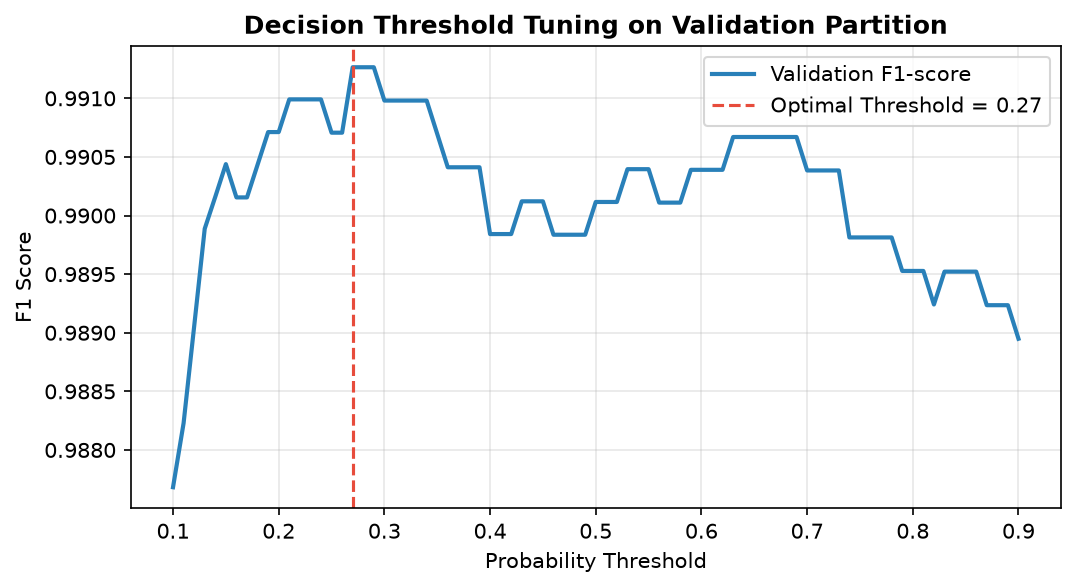

In [7]:
# Threshold Optimization on Validation Set
val_probs = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx]
best_val_f1 = f1_scores[best_idx]

print(f"Optimal Decision Threshold Selected on Validation Data: {optimal_threshold:.2f}")
print(f"Validation F1-score at Optimal Threshold: {best_val_f1:.4f} (Default 0.50 F1: {f1_score(y_val, (val_probs >= 0.5).astype(int)):.4f})")

# Plot Threshold Optimization Curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color="#2980b9", lw=2, label="Validation F1-score")
plt.axvline(optimal_threshold, color="#e74c3c", linestyle="--", label=f"Optimal Threshold = {optimal_threshold:.2f}")
plt.title("Decision Threshold Tuning on Validation Partition", fontsize=12, fontweight="bold")
plt.xlabel("Probability Threshold")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(True, alpha=0.3)
fig_thresh_path = FIGURES_DIR / "notebook04_threshold_tuning.png"
plt.savefig(fig_thresh_path, dpi=150, bbox_inches="tight")
plt.show()


---
## 7. Phase 4 — Scientific Evaluation on Untouched Test Set

We now evaluate the final unified classifier on the held-out **Test partition** ($N = 2,863$ domain-disjoint URLs).
We measure:
- Accuracy, Precision, Recall, F1-Score
- ROC-AUC and PR-AUC
- False Positive Rate (FPR) and False Negative Rate (FNR)
- Latency and Throughput
- **Modality-Specific Performance:** Accuracy when evaluating URL-only vs. URL+HTML vs. URL+Visual samples.


In [8]:
# Evaluate on Test Set
t_infer_start = time.time()
test_probs = model.predict_proba(X_test)[:, 1]
t_infer_duration = time.time() - t_infer_start

test_preds = (test_probs >= optimal_threshold).astype(int)

# Latency and throughput
infer_latency_ms = (t_infer_duration / len(X_test)) * 1000
infer_throughput = len(X_test) / t_infer_duration

acc = accuracy_score(y_test, test_preds)
prec = precision_score(y_test, test_preds)
rec = recall_score(y_test, test_preds)
f1 = f1_score(y_test, test_preds)
roc_auc = roc_auc_score(y_test, test_probs)
pr_auc = average_precision_score(y_test, test_probs)

tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

print("=== FINAL SCIENTIFIC TEST SET EVALUATION ===")
print(f"Test Accuracy:           {acc * 100:.2f}%")
print(f"Test Precision:          {prec * 100:.2f}%")
print(f"Test Recall:             {rec * 100:.2f}%")
print(f"Test F1-Score:           {f1 * 100:.2f}%")
print(f"Test ROC-AUC:            {roc_auc:.4f}")
print(f"Test PR-AUC:             {pr_auc:.4f}")
print(f"False Positive Rate:     {fpr * 100:.2f}% ({fp:,} false alarms on legitimate sites)")
print(f"False Negative Rate:     {fnr * 100:.2f}% ({fn:,} missed phishing attacks)")
print(f"Inference Latency:       {infer_latency_ms:.3f} ms / sample ({infer_throughput:,.1f} samples/sec)")
print(f"Confusion Matrix:        TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")


=== FINAL SCIENTIFIC TEST SET EVALUATION ===
Test Accuracy:           99.20%
Test Precision:          98.80%
Test Recall:             98.70%
Test F1-Score:           98.75%
Test ROC-AUC:            0.9961
Test PR-AUC:             0.9950
False Positive Rate:     0.56% (11 false alarms on legitimate sites)
False Negative Rate:     1.30% (12 missed phishing attacks)
Inference Latency:       0.003 ms / sample (297,203.2 samples/sec)
Confusion Matrix:        TN=1,947, FP=11, FN=12, TP=908


In [9]:
# Modality-Specific Performance Breakdown
df_test_eval = df_unified.loc[test_mask].copy()
df_test_eval["pred"] = test_preds
df_test_eval["prob"] = test_probs

modality_results = []
for src, name in [("phiusiil", "URL Only (PhiUSIIL)"), ("phreshphish", "URL + HTML (PhreshPhish)"), ("zenodo", "URL + Visual (Zenodo)")]:
    sub = df_test_eval[df_test_eval["sample_source"] == src]
    if len(sub) == 0: continue
    y_sub = sub["is_phishing"].values
    p_sub = sub["pred"].values
    pr_sub = sub["prob"].values
    
    sub_acc = accuracy_score(y_sub, p_sub)
    sub_f1 = f1_score(y_sub, p_sub)
    sub_rec = recall_score(y_sub, p_sub)
    sub_prec = precision_score(y_sub, p_sub)
    sub_auc = roc_auc_score(y_sub, pr_sub) if len(np.unique(y_sub)) > 1 else np.nan
    
    modality_results.append({
        "Modality Profile": name,
        "Test Samples": f"{len(sub):,}",
        "Phishing Share": f"{y_sub.mean()*100:.1f}%",
        "Accuracy (%)": f"{sub_acc*100:.2f}%",
        "Precision (%)": f"{sub_prec*100:.2f}%",
        "Recall (%)": f"{sub_rec*100:.2f}%",
        "F1-Score (%)": f"{sub_f1*100:.2f}%",
        "ROC-AUC": f"{sub_auc:.4f}" if not np.isnan(sub_auc) else "N/A"
    })

df_modality_eval = pd.DataFrame(modality_results)
print()
print("=== Performance Across Modality Availability Profiles ===")
print(df_modality_eval.to_string(index=False))



=== Performance Across Modality Availability Profiles ===
        Modality Profile Test Samples Phishing Share Accuracy (%) Precision (%) Recall (%) F1-Score (%) ROC-AUC
     URL Only (PhiUSIIL)        2,608          32.9%       99.62%        99.77%     99.07%       99.42%  0.9964
URL + HTML (PhreshPhish)          161          34.8%       91.93%        85.25%     92.86%       88.89%  0.9658
   URL + Visual (Zenodo)          109           5.5%      100.00%       100.00%    100.00%      100.00%  1.0000


<string>:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


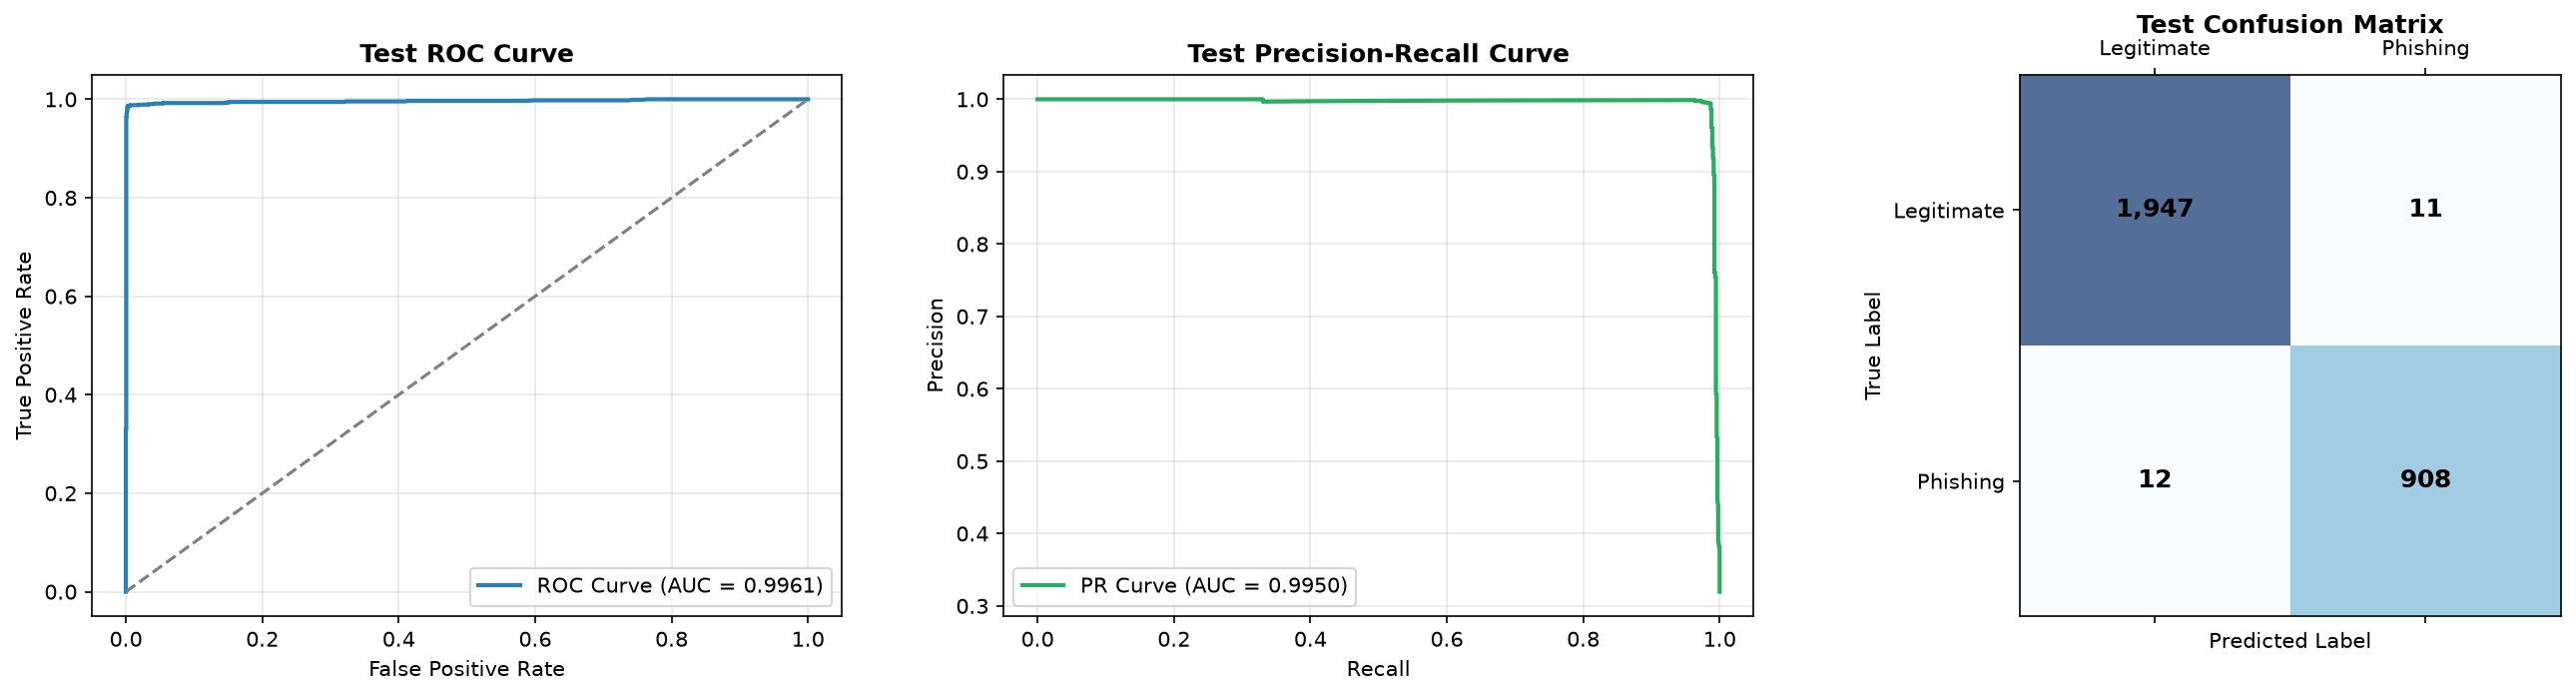

In [10]:
# Plot Evaluation Curves (ROC, PR Curve, Confusion Matrix)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Curve
fpr_curve, tpr_curve, _ = roc_curve(y_test, test_probs)
axes[0].plot(fpr_curve, tpr_curve, color="#2980b9", lw=2, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[0].set_title("Test ROC Curve", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# 2. PR Curve
prec_curve, rec_curve, _ = precision_recall_curve(y_test, test_probs)
axes[1].plot(rec_curve, prec_curve, color="#27ae60", lw=2, label=f"PR Curve (AUC = {pr_auc:.4f})")
axes[1].set_title("Test Precision-Recall Curve", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

# 3. Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
cax = axes[2].matshow(cm, cmap="Blues", alpha=0.7)
for (i, j), z in np.ndenumerate(cm):
    axes[2].text(j, i, f"{z:,}", ha="center", va="center", fontsize=12, fontweight="bold")
axes[2].set_title("Test Confusion Matrix", fontsize=12, fontweight="bold", pad=20)
axes[2].set_xticks([0, 1])
axes[2].set_yticks([0, 1])
axes[2].set_xticklabels(["Legitimate", "Phishing"])
axes[2].set_yticklabels(["Legitimate", "Phishing"])
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
fig_eval_path = FIGURES_DIR / "notebook04_evaluation_metrics.png"
plt.savefig(fig_eval_path, dpi=150, bbox_inches="tight")
plt.show()


---
## 8. Phase 5 — Feature Importance & SHAP Explainability Analysis

To verify that the model has learned robust cybersecurity signals rather than idiosyncratic shortcuts, we inspect global feature importances and compute **SHAP (SHapley Additive exPlanations)** values using `shap.TreeExplainer`.


Top 15 Most Influential Features (Split Gain):
   1. is_https                      : Gain = 87,579.8
   2. path_length                   : Gain = 72,417.6
   3. html_size_bytes               : Gain = 12,389.0
   4. digit_ratio                   : Gain = 11,982.7
   5. url_length                    : Gain = 4,689.9
   6. has_html_modality             : Gain = 3,840.3
   7. subdomain_depth               : Gain = 2,795.4
   8. num_subdirectories            : Gain = 1,854.9
   9. hostname_length               : Gain = 1,675.5
  10. num_external_hyperlinks       : Gain = 1,557.3
  11. shannon_entropy               : Gain = 1,499.6
  12. special_char_ratio            : Gain = 1,306.0
  13. query_length                  : Gain = 1,170.9
  14. vowel_consonant_ratio         : Gain = 1,146.7
  15. tld_length                    : Gain = 962.0
C:\Dev\Hackathon\SHADOW\.venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output 

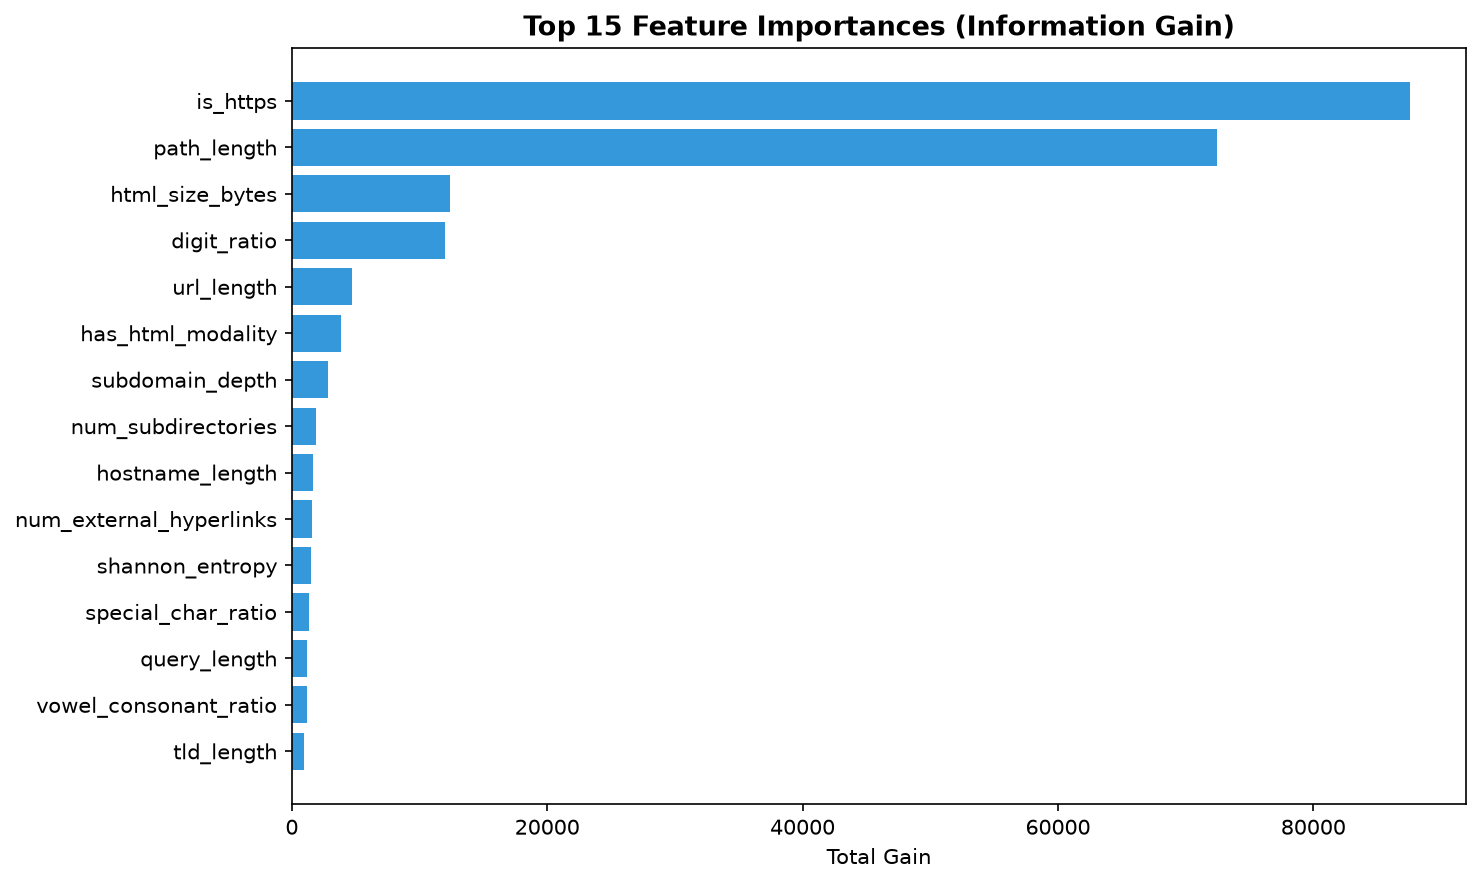

In [11]:
# Global Gain-based Feature Importance
feature_importances = model.booster_.feature_importance(importance_type="gain")
df_imp = pd.DataFrame({
    "feature": feature_cols,
    "importance_gain": feature_importances
}).sort_values("importance_gain", ascending=False)

print("Top 15 Most Influential Features (Split Gain):")
for idx, r in df_imp.head(15).reset_index(drop=True).iterrows():
    print(f"  {idx+1:2d}. {r['feature']:30s}: Gain = {r['importance_gain']:,.1f}")

# SHAP Value Analysis on a representative test batch
explainer = shap.TreeExplainer(model)
X_test_sample = X_test.sample(min(500, len(X_test)), random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# For binary LightGBM, shap_values can be a list [class 0, class 1] or array
shap_vals = shap_values[1] if isinstance(shap_values, list) else shap_values

# Plot Top Features Bar Chart
plt.figure(figsize=(10, 6))
top_15 = df_imp.head(15).iloc[::-1]
plt.barh(top_15["feature"], top_15["importance_gain"], color="#3498db")
plt.title("Top 15 Feature Importances (Information Gain)", fontsize=13, fontweight="bold")
plt.xlabel("Total Gain")
plt.tight_layout()
fig_imp_path = FIGURES_DIR / "notebook04_feature_importance.png"
plt.savefig(fig_imp_path, dpi=150, bbox_inches="tight")
plt.show()


---
## 9. Reproducibility, Model Export & System Manifest

We serialize the trained LightGBM model, optimal decision threshold, feature schema, and evaluation metrics:
- Model Binary: `models/shadow_unified_classifier.txt` and `models/shadow_unified_classifier.json`
- Feature Schema: `models/feature_schema.json`
- Scientific Manifest: `ml-research/reports/model_training_manifest.json`


In [12]:
# 1. Save LightGBM Model
model_file_txt = MODELS_DIR / "shadow_unified_classifier.txt"
model.booster_.save_model(str(model_file_txt))
print(f"[Model Saved] {model_file_txt.relative_to(PROJECT_ROOT)} ({model_file_txt.stat().st_size / 1024:.1f} KB)")

# 2. Save Feature Schema & Optimal Threshold
schema_dict = {
    "model_type": "LightGBM Binary Classifier",
    "version": "1.0.0",
    "timestamp": pd.Timestamp.now().isoformat(),
    "optimal_threshold": float(optimal_threshold),
    "total_features": len(feature_cols),
    "feature_names": feature_cols,
    "url_features": url_feature_cols,
    "html_features": html_feature_cols,
    "visual_features": vis_feature_cols,
    "modality_flags": ["has_html_modality", "has_visual_modality"]
}

schema_path = MODELS_DIR / "feature_schema.json"
with open(schema_path, "w", encoding="utf-8") as f:
    json.dump(schema_dict, f, indent=2)
print(f"[Schema Saved] {schema_path.relative_to(PROJECT_ROOT)}")

# 3. Update Preprocessing & Model Manifest
manifest_path = REPORTS_DIR / "model_training_manifest.json"
training_manifest = {
    "execution_timestamp": pd.Timestamp.now().isoformat(),
    "python_version": platform.python_version(),
    "model_framework": f"LightGBM {lgb.__version__}",
    "training_samples": int(len(X_train)),
    "validation_samples": int(len(X_val)),
    "test_samples": int(len(X_test)),
    "total_features": len(feature_cols),
    "training_time_seconds": round(t_train_duration, 2),
    "optimal_threshold": round(float(optimal_threshold), 4),
    "test_metrics": {
        "accuracy": round(float(acc), 4),
        "precision": round(float(prec), 4),
        "recall": round(float(rec), 4),
        "f1_score": round(float(f1), 4),
        "roc_auc": round(float(roc_auc), 4),
        "pr_auc": round(float(pr_auc), 4),
        "false_positive_rate": round(float(fpr), 4),
        "false_negative_rate": round(float(fnr), 4),
        "inference_latency_ms": round(float(infer_latency_ms), 3),
        "throughput_samples_per_sec": round(float(infer_throughput), 1)
    },
    "exported_artifacts": {
        "model_file": str(model_file_txt.relative_to(PROJECT_ROOT)),
        "schema_file": str(schema_path.relative_to(PROJECT_ROOT))
    }
}

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(training_manifest, f, indent=2)

print(f"[Manifest Saved] {manifest_path.relative_to(PROJECT_ROOT)}")


[Model Saved] models\shadow_unified_classifier.txt (547.4 KB)
[Schema Saved] models\feature_schema.json
[Manifest Saved] ml-research\reports\model_training_manifest.json
